# Customer Churn Prediction

Predicting which banking customers are likely to leave using a leakage-aware preprocessing pipeline, class weighting, and model comparison.

**Author:** Patrick Felder | TripleTen coursework project

Place the authorized `Churn.csv` dataset in `data/`, or set `CHURN_DATA_PATH`. Recorded outputs come from the original coursework run; the adjusted portable notebook has not been rerun.


In [1]:
import os
from pathlib import Path
import pandas as pd

dataset_path = Path(os.environ.get('CHURN_DATA_PATH', 'data/Churn.csv'))
if not dataset_path.exists() and Path('/datasets/Churn.csv').exists():
    dataset_path = Path('/datasets/Churn.csv')
if not dataset_path.exists():
    raise FileNotFoundError('Place Churn.csv in data/ or set CHURN_DATA_PATH.')
df = pd.read_csv(dataset_path)
print(df.shape)
print(df.info())
print(df.isna().sum())


(10000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB
None
RowNumber            0
CustomerId           0
Surname              0
CreditSc

## Data preparation and class balance

The source contains 10,000 records and 14 columns. `Tenure` has 909 missing values. `RowNumber`, `CustomerId`, and `Surname` are excluded from model features; `Exited` is the binary target. Preprocessing is fitted within each model pipeline.


In [4]:
# These are identifiers / non-predictive text fields for ML
drop_cols = ['RowNumber', 'CustomerId', 'Surname']

X = df.drop(columns=drop_cols + ['Exited'])
y = df['Exited']


0    0.7963
1    0.2037
Name: Exited, dtype: float64


<AxesSubplot:>

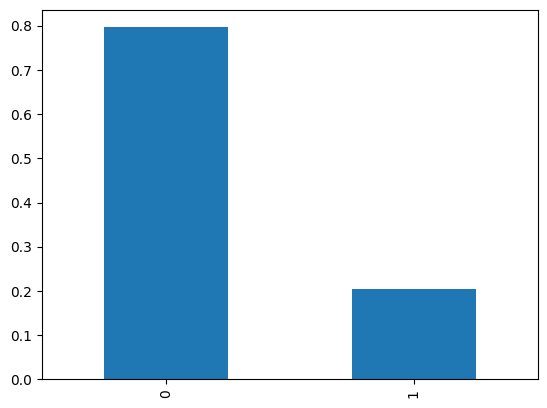

In [5]:
class_freq = y.value_counts(normalize=True)
print(class_freq)
class_freq.plot(kind='bar')


In [6]:
from sklearn.model_selection import train_test_split

# First split off test set
X_train_valid, X_test, y_train_valid, y_test = train_test_split(
    X, y, test_size=0.2, random_state=12345, stratify=y
)

# Then split train/valid
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_valid, y_train_valid, test_size=0.25, random_state=12345, stratify=y_train_valid
)

print(X_train.shape, X_valid.shape, X_test.shape)


(6000, 10) (2000, 10) (2000, 10)


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

cat_cols = X_train.select_dtypes(include='object').columns
num_cols = X_train.select_dtypes(exclude='object').columns

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

preprocess = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', categorical_pipe, cat_cols)
])


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score

baseline = Pipeline([
    ('prep', preprocess),
    ('model', LogisticRegression(max_iter=2000, random_state=12345))
])

baseline.fit(X_train, y_train)

pred_valid = baseline.predict(X_valid)
proba_valid = baseline.predict_proba(X_valid)[:, 1]

print("Baseline F1:", f1_score(y_valid, pred_valid))
print("Baseline AUC-ROC:", roc_auc_score(y_valid, proba_valid))


Baseline F1: 0.3214953271028037
Baseline AUC-ROC: 0.7874345840447535


In [9]:
weighted_lr = Pipeline([
    ('prep', preprocess),
    ('model', LogisticRegression(
        max_iter=2000,
        random_state=12345,
        class_weight='balanced'
    ))
])

weighted_lr.fit(X_train, y_train)
pred_valid = weighted_lr.predict(X_valid)
proba_valid = weighted_lr.predict_proba(X_valid)[:, 1]

print("Weighted LR F1:", f1_score(y_valid, pred_valid))
print("Weighted LR AUC-ROC:", roc_auc_score(y_valid, proba_valid))


Weighted LR F1: 0.5108601216333623
Weighted LR AUC-ROC: 0.7917578595544696


In [10]:

from sklearn.metrics import classification_report, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([
    ('prep', preprocess),
    ('model', RandomForestClassifier(random_state=12345, n_jobs=-1, class_weight='balanced'))
])

param_grid = {
    'model__n_estimators': [200, 400, 600],
    'model__max_depth': [8, 10, 12, None],
    'model__min_samples_leaf': [1, 2, 4]
}

grid = GridSearchCV(
    rf,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print("Best params:", grid.best_params_)

pred_valid = best_model.predict(X_valid)
proba_valid = best_model.predict_proba(X_valid)[:, 1]

print("Best RF F1 (valid):", f1_score(y_valid, pred_valid))
print("Best RF AUC-ROC (valid):", roc_auc_score(y_valid, proba_valid))



Best params: {'model__max_depth': 12, 'model__min_samples_leaf': 4, 'model__n_estimators': 600}
Best RF F1 (valid): 0.6456310679611651
Best RF AUC-ROC (valid): 0.8699007173583444


## Interpretation

Churn represents 20.37% of records. Logistic Regression validation F1 rose from 0.3215 to 0.5109 with class weighting. The tuned Random Forest achieved validation F1 0.6456. After refitting on training plus validation data, the final model achieved test F1 0.6492 and ROC-AUC 0.8671 on 2,000 held-out customers, exceeding the coursework F1 target of 0.59.

The code uses class weighting, not resampling. These results support a churn classification prototype; no live retention impact was measured.


In [11]:
# Retrain best model on train + validation
X_train_final = pd.concat([X_train, X_valid])
y_train_final = pd.concat([y_train, y_valid])

best_model.fit(X_train_final, y_train_final)

# Test predictions
pred_test = best_model.predict(X_test)
proba_test = best_model.predict_proba(X_test)[:, 1]

# Metrics
print("TEST F1:", f1_score(y_test, pred_test))
print("TEST AUC-ROC:", roc_auc_score(y_test, proba_test))
print("\nClassification Report:\n")
print(classification_report(y_test, pred_test))


TEST F1: 0.6491646778042959
TEST AUC-ROC: 0.8671475790119858

Classification Report:

              precision    recall  f1-score   support

           0       0.91      0.90      0.91      1593
           1       0.63      0.67      0.65       407

    accuracy                           0.85      2000
   macro avg       0.77      0.78      0.78      2000
weighted avg       0.86      0.85      0.85      2000

